# Proyek Klasifikasi Tutupan Lahan (LULC) Provinsi Jawa Timur
Menggunakan Citra Satelit Sentinel-2A, Indeks Spektral, Machine Learning, dan Web GIS



---
## Fase 1: Data Understanding & Pendefinisian Tujuan

### 1.1 Tujuan Analisis Land Use and Land Cover (LULC)
Tujuan utama analisis ini adalah untuk **memetakan kondisi tutupan lahan aktual di Jawa Timur** sebagai dasar evaluasi **Rencana Tata Ruang Wilayah (RTRW)**. Analisis ini memberikan wawasan kuantitatif dan spasial bagi pengambil kebijakan dalam:
1. **Memantau Alih Fungsi Lahan**: Mendeteksi penyusutan lahan hijau dan lahan pertanian produktif yang berubah menjadi kawasan terbangun/industri.
2. **Konservasi Ekosistem Pesisir**: Memantau degradasi maupun suksesi hutan mangrove di kawasan pesisir Jawa Timur.
3. **Perlindungan Resapan Air**: Melindungi dan memonitor kawasan tubuh air pedalaman seperti danau (*ranu*) di kawasan dataran tinggi dan vulkanik.
4. **Optimalisasi Ketahanan Pangan**: Menjaga luas baku lahan sawah agar ketahanan pangan regional tetap terjaga.

### 1.2 Acuan Klasifikasi Lahan di Indonesia (SNI 7645-1:2014)
Klasifikasi tidak hanya membagi sawah dan non-sawah, tetapi mengacu pada **Standar Nasional Indonesia (SNI) 7645-1:2014** tentang *Klasifikasi Penutup Lahan*. Hierarki ini mencakup:
- **Daerah Bervegetasi**: Pertanian (Sawah), Hutan/Vegetasi Alami (Lahan Hijau), Hutan Pasang Surut (Mangrove).
- **Daerah Tak Bervegetasi**: Lahan Terbangun / Permukiman (Bangunan).
- **Tubuh Air**: Perairan Darat (Danau/Ranu) dan Perairan Laut (Laut/Pesisir).

### 1.3 Ke-6 Kelas yang Digunakan
| Kode Label | Nama Kelas | Definisi Spasial | Acuan Warna |
| :---: | :--- | :--- | :--- |
| **0** | **Sawah** | Lahan pertanian tanaman pangan basah / padi | Kuning (`#FFD700`) |
| **1** | **Bangunan** | Area permukiman, kawasan industri, dan infrastruktur terbangun | Merah (`#FF0000`) |
| **2** | **Danau (Ranu)** | Badan air tergenang pedalaman / air tawar alami | Biru Muda (`#00BFFF`) |
| **3** | **Lahan Hijau** | Hutan alami, perkebunan, semak belukar, dan vegetasi non-sawah | Hijau (`#228B22`) |
| **4** | **Mangrove** | Komunitas vegetasi hutan pantai / pasang surut | Ungu (`#800080`) |
| **5** | **Laut (Perairan Terbuka)** | Tubuh air asin laut lepas dan perairan pesisir | Biru Tua (`#00008B`) |


---
## Fase 2: Data Collecting (Pengumpulan Data & Crawling OpenEO)

### 2.1 Sumber Data & Area Studi
- **Sensor**: Sentinel-2A MSI (MultiSpectral Instrument).
- **Tingkat Produk (Level)**: **Level-2A (L2A)** - *Bottom of Atmosphere (BOA) / Surface Reflectance*, sehingga nilai pantulan telah dikoreksi secara geometrik dan radiometrik serta bebas dari efek hamburan atmosfer.
- **Area Studi (ROI)**: Provinsi Jawa Timur (meliputi daratan utama Jawa bagian timur dan Kepulauan Madura).
- **Waktu Perekaman**: Komposit median temporal periode Juni - September dengan filter tutupan awan (*cloud cover*) < 10% (median awan < 5%) untuk menghasilkan citra mosaik yang bersih dari tutupan awan.

### 2.2 Alur Pemrosesan Crawling Citra Satelit:
1. **Membaca Shapefile Sampel**: Membaca 6 berkas poligon ROI (`sawah.zip`, `bangunan.zip`, `danau.zip`, `lahan_hijau.zip`, `mangrove.zip`, `laut.zip`).
2. **Standardisasi Sistem Koordinat**: Transformasi seluruh koordinat ke WGS 84 (`EPSG:4326`).
3. **Pembersihan Geometri**: Menjalankan `.make_valid()` dan menghapus poligon kosong/null.
4. **Perhitungan Bounding Box**: Menghitung koordinat batas wilayah gabungan untuk mendefinisikan *spatial extent*.
5. **Koneksi OpenEO**: Terhubung ke Copernicus Data Space Ecosystem (`openeo.dataspace.copernicus.eu`).
6. **Mosaik & Reduksi Spasial**: Membentuk komposit median bebas awan dan mereduksi nilai piksel poligon secara rata-rata (`aggregate_spatial(reducer="mean")`).
7. **Eksekusi Batch Job Asinkron**: Menjalankan ekstraksi di server backend OpenEO untuk menghindari limit timeout jaringan.
8. **Transformasi JSON ke CSV**: Mengurai array piksel spektral dan menyimpannya sebagai tabel `dataset_sentinel2_jatim.csv`.


In [11]:
!pip install geopandas openeo pandas scikit-learn xgboost lightgbm folium matplotlib seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\HYPE AMD\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [12]:
import geopandas as gpd
import openeo
import pandas as pd
import json

# ==============================================================================
# 1. BACA KEDUA FILE ZIP DAN BERI LABEL OTOMATIS
# ==============================================================================
gdf_sawah = gpd.read_file("sawah.zip").to_crs("EPSG:4326")
gdf_bangunan = gpd.read_file("bangunan.zip").to_crs("EPSG:4326")
gdf_danau = gpd.read_file("danau.zip").to_crs("EPSG:4326")
gdf_lahan_hijau = gpd.read_file("lahan_hijau.zip").to_crs("EPSG:4326")
gdf_mangrove = gpd.read_file("mangrove.zip").to_crs("EPSG:4326")
gdf_laut = gpd.read_file("laut.zip").to_crs("EPSG:4326")

gdf_sawah["label_teks"], gdf_sawah["label"] = "sawah", 0
gdf_bangunan["label_teks"], gdf_bangunan["label"] = "bangunan", 1
gdf_danau["label_teks"], gdf_danau["label"] = "danau", 2
gdf_lahan_hijau["label_teks"], gdf_lahan_hijau["label"] = "lahan_hijau", 3
gdf_mangrove["label_teks"], gdf_mangrove["label"] = "mangrove", 4
gdf_laut["label_teks"], gdf_laut["label"] = "laut", 5

# Gabungkan menjadi 1 GeoDataFrame
gdf_gabungan = gpd.GeoDataFrame(
    pd.concat([gdf_sawah, gdf_bangunan, gdf_danau, gdf_lahan_hijau, gdf_mangrove, gdf_laut], ignore_index=True),
    crs="EPSG:4326"
)

# === [ TAMBAHAN KODE PERBAIKAN DI SINI ] ===
# 1. Buang data yang geometrinya kosong (None)
gdf_gabungan["geometry"] = gdf_gabungan.make_valid()
gdf_gabungan = gdf_gabungan.dropna(subset=["geometry"]).reset_index(drop=True)

# 2. Ubah format GeoDataFrame ke dictionary GeoJSON agar 100% kompatibel dengan OpenEO
geojson_gabungan = json.loads(gdf_gabungan.to_json())
# ===========================================

# ==============================================================================
# 2. AMBIL BATAS KOORDINAT GABUNGAN (BOUNDING BOX)
# ==============================================================================
minx, miny, maxx, maxy = gdf_gabungan.total_bounds
bbox = {
    "west": float(minx),
    "south": float(miny),
    "east": float(maxx),
    "north": float(maxy),
}

# ==============================================================================
# 3. KONEKSI KE OPENEO & EKSTRAKSI NILAI PIKSEL
# ==============================================================================
conn = openeo.connect("openeo.dataspace.copernicus.eu")
conn.authenticate_oidc()

datacube = conn.load_collection(
    "SENTINEL2_L2A",
    spatial_extent=bbox,
    temporal_extent=["2026-06-01", "2026-09-30"],
    bands=["B02", "B03", "B04", "B08", "B11"],
    max_cloud_cover=10,
)

composite_s2 = datacube.median_time()

# EKSTRAKSI LANGSUNG DI SERVER (Gunakan geojson_gabungan, BUKAN gdf_gabungan)
print("Meminta ekstraksi nilai piksel dari server OpenEO...")
aggregated_data = composite_s2.aggregate_spatial(geometries=geojson_gabungan, reducer="mean")

# ==============================================================================
# ==============================================================================
# JALANKAN PROSES MENGGUNAKAN BATCH JOB
# ==============================================================================
# Catatan: Area seluruh Jawa Timur sangat luas, proses sinkronus (.download())
# melebihi batas waktu 30 menit (ReadTimeoutError). Dengan Batch Job, proses berjalan
# di backend server OpenEO tanpa batas timeout koneksi.
hasil_json = 'hasil_ekstraksi.json'
print('Membuat Batch Job di server OpenEO...')
job = aggregated_data.create_job(title='Ekstraksi Sentinel-2 6 Kelas Jatim', out_format='JSON')
print(f'Batch Job berhasil dibuat! Job ID: {job.job_id}')

# Jalankan dan pantau progres hingga selesai
print('Menjalankan dan memantau progres job (start_and_wait)...')
job.start_and_wait()

# Unduh hasil setelah selesai
print('Mengunduh hasil ekstraksi...')
results = job.get_results()
results.download_file(hasil_json)
print(f'Ekstraksi selesai! File berhasil disimpan di: {hasil_json}')


Authenticated using refresh token.
Meminta ekstraksi nilai piksel dari server OpenEO...
Membuat Batch Job di server OpenEO...
Batch Job berhasil dibuat! Job ID: j-2610111404304cf093c233ebdaf49496
Menjalankan dan memantau progres job (start_and_wait)...
0:00:00 Job 'j-2610111404304cf093c233ebdaf49496': send 'start'
0:00:04 Job 'j-2610111404304cf093c233ebdaf49496': queued (progress 0%)
0:00:11 Job 'j-2610111404304cf093c233ebdaf49496': queued (progress 0%)
0:00:19 Job 'j-2610111404304cf093c233ebdaf49496': queued (progress 0%)
0:00:28 Job 'j-2610111404304cf093c233ebdaf49496': queued (progress 0%)
0:00:42 Job 'j-2610111404304cf093c233ebdaf49496': queued (progress 0%)
0:00:59 Job 'j-2610111404304cf093c233ebdaf49496': running (progress N/A)
0:01:18 Job 'j-2610111404304cf093c233ebdaf49496': running (progress N/A)
0:01:41 Job 'j-2610111404304cf093c233ebdaf49496': running (progress N/A)
0:02:11 Job 'j-2610111404304cf093c233ebdaf49496': running (progress N/A)
0:02:45 Job 'j-2610111404304cf093c233

In [13]:
# ==============================================================================
# 4. GABUNGKAN HASIL JSON KE CSV (PERBAIKAN ALIGNMENT LABEL)
# ==============================================================================
import os, glob

# Pastikan file JSON ditemukan
if not os.path.exists(hasil_json):
    for pf in glob.glob("*.json"):
        if any(keyword in pf.lower() for keyword in ["ekstraksi", "timeseries", "result"]):
            hasil_json = pf
            break

print(f"Membaca hasil dari: {hasil_json}")
with open(hasil_json, 'r') as f:
    data_openeo = json.load(f)

extracted_rows = []

# Iterasi secara eksplisit menggunakan index numerik dari gdf_gabungan 
# Ini untuk mencegah fitur tertukar labelnya karena JSON mengurutkan secara alfabetis
for i in range(len(gdf_gabungan)):
    key = str(i) # ID OpenEO adalah string dari index GeoJSON
    vals = None
    
    # Ekstraksi yang aman (Mapping ID ke Value)
    if isinstance(data_openeo, dict) and key in data_openeo:
        item = data_openeo[key]
        if isinstance(item, list) and len(item) > 0 and isinstance(item[0], list):
            vals = item[0]
        elif isinstance(item, list):
            vals = item
    elif isinstance(data_openeo, list) and i < len(data_openeo):
        item = data_openeo[i]
        if isinstance(item, list) and len(item) > 0 and isinstance(item[0], list):
            vals = item[0]
        elif isinstance(item, list):
            vals = item

    # Ekstrak nilai band jika valid dan gabungkan langsung dengan label yang BENAR
    if vals is not None and len(vals) >= 5:
        row_data = {
            "B02": vals[0],
            "B03": vals[1],
            "B04": vals[2],
            "B08": vals[3],
            "B11": vals[4],
            "label_teks": gdf_gabungan.loc[i, 'label_teks'],
            "label": gdf_gabungan.loc[i, 'label']
        }
    else:
        row_data = {
            "B02": None, "B03": None, "B04": None, "B08": None, "B11": None,
            "label_teks": gdf_gabungan.loc[i, 'label_teks'],
            "label": gdf_gabungan.loc[i, 'label']
        }
    extracted_rows.append(row_data)

# Jadikan DataFrame final
df_final = pd.DataFrame(extracted_rows)

# Buang baris yang nilai band-nya kosong/None
df_final = df_final.dropna(subset=['B02']).reset_index(drop=True)

# Simpan ke CSV
nama_csv = "dataset_sentinel2_jatim.csv"
df_final.to_csv(nama_csv, index=False)
print(f"File berhasil disimpan sebagai: {nama_csv}")
df_final.head()

Membaca hasil dari: hasil_ekstraksi.json
File berhasil disimpan sebagai: dataset_sentinel2_jatim.csv


,B02,B03,B04,B08,B11,label_teks,label
0,714.219697,969.257576,1024.409091,2943.984848,2847.348485,sawah,0
1,500.292056,707.990654,594.682243,2276.556075,1540.556075,sawah,0
2,496.301848,817.334702,1155.971253,2727.616016,3711.014374,sawah,0
3,541.558559,810.486486,832.211712,3375.148649,2643.238739,sawah,0
4,387.692508,648.623453,496.523127,1429.024756,745.904235,sawah,0


---
## Fase 3: Ekstraksi Fitur & Penjelasan Band Sentinel-2A

### 3.1 Deskripsi Band Sentinel-2A yang Digunakan
| Band | Nama Band | Panjang Gelombang Sentral | Resolusi Spasial | Kegunaan Utama dalam LULC |
| :---: | :---: | :---: | :---: | :--- |
| **B02** | Blue | ~492 nm | 10 m | Pemetaan batimetri, perairan pesisir, pembeda tanah dan vegetasi |
| **B03** | Green | ~560 nm | 10 m | Analisis puncak pantulan klorofil vegetasi sehat & tubuh air |
| **B04** | Red | ~665 nm | 10 m | Analisis serapan klorofil tanaman, klasifikasi lahan terbangun |
| **B08** | NIR (Near Infrared) | ~842 nm | 10 m | Sangat sensitif terhadap struktur sel mesofil biomassa vegetasi dan penyerapan air |
| **B11** | SWIR 1 | ~1610 nm | 20 m | Analisis kelembaban daun, kadar air kanopi, dan kelembaban tanah |
| **B12** | SWIR 2 | ~2190 nm | 20 m | Identifikasi mineral batuan, tanah terbuka, dan area terbangun padat |

### 3.2 Fitur Tambahan (Spectral Indices) beserta Rumusnya
Untuk mempertegas separabilitas spektral antar kelas tutupan lahan yang sering kali tumpang-tindih (*overlapping*), kita mentransformasikan band dasar ke dalam indeks spektral ternormalisasi:

1. **NDVI (Normalized Difference Vegetation Index)**
   Membedakan lahan hijau, mangrove, dan sawah dari objek non-vegetasi.
   $$\text{NDVI} = \frac{B08 - B04}{B08 + B04}$$

2. **NDWI (Normalized Difference Water Index - McFeeters)**
   Mengidentifikasi tubuh air terbuka (laut, danau) dengan memanfaatkan serapan NIR dan reflektansi Green.
   $$\text{NDWI} = \frac{B03 - B08}{B03 + B08}$$

3. **MNDWI (Modified Normalized Difference Water Index - Xu)**
   Menggantikan band NIR dengan SWIR1 sehingga lebih efektif memisahkan badan air tenang dari lahan terbangun perkotaan.
   $$\text{MNDWI} = \frac{B03 - B11}{B03 + B11}$$

4. **NDBI (Normalized Difference Built-up Index)**
   Menonjolkan lahan terbangun (bangunan, jalan, pemukiman) yang memiliki pantulan SWIR1 lebih tinggi daripada NIR.
   $$\text{NDBI} = \frac{B11 - B08}{B11 + B08}$$


In [14]:
# Import pustaka utama
import os
import json
import joblib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import xgboost as xgb
import lightgbm as lgb
import folium
from folium import LayerControl

# Atur style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Arial'


In [15]:
# 1. Membaca dataset hasil crawling OpenEO
csv_input = "dataset_sentinel2_jatim.csv"
df_raw = pd.read_csv(csv_input)

print(f"Dataset berhasil dimuat: {len(df_raw)} baris, {df_raw.shape[1]} kolom.")
df_raw.head()


Dataset berhasil dimuat: 300 baris, 7 kolom.


,B02,B03,B04,B08,B11,label_teks,label
0,714.219697,969.257576,1024.409091,2943.984848,2847.348485,sawah,0
1,500.292056,707.990654,594.682243,2276.556075,1540.556075,sawah,0
2,496.301848,817.334702,1155.971253,2727.616016,3711.014374,sawah,0
3,541.558559,810.486486,832.211712,3375.148649,2643.238739,sawah,0
4,387.692508,648.623453,496.523127,1429.024756,745.904235,sawah,0


In [16]:
# 2. Komputasi Spectral Indices (NDVI, NDWI, MNDWI, NDBI)
eps = 1e-8  # epsilon untuk mencegah pembagian dengan nol

df = df_raw.copy()
df['NDVI'] = (df['B08'] - df['B04']) / (df['B08'] + df['B04'] + eps)
df['NDWI'] = (df['B03'] - df['B08']) / (df['B03'] + df['B08'] + eps)
df['MNDWI'] = (df['B03'] - df['B11']) / (df['B03'] + df['B11'] + eps)
df['NDBI'] = (df['B11'] - df['B08']) / (df['B11'] + df['B08'] + eps)

# Susun urutan kolom fitur yang rapi
feature_cols = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']
df_features = df[feature_cols + ['label_teks', 'label']]

# Simpan ke CSV dataset yang telah diperkaya fitur spektral
csv_features = "dataset_sentinel2_jatim_features.csv"
df_features.to_csv(csv_features, index=False)
print(f"Dataset dengan fitur lengkap berhasil disimpan ke: {csv_features}")
df_features.head()


Dataset dengan fitur lengkap berhasil disimpan ke: dataset_sentinel2_jatim_features.csv


,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI,label_teks,label
0,714.219697,969.257576,1024.409091,2943.984848,2847.348485,0.483716,-0.504627,-0.492084,-0.016686,sawah,0
1,500.292056,707.990654,594.682243,2276.556075,1540.556075,0.585766,-0.525562,-0.370268,-0.192816,sawah,0
2,496.301848,817.334702,1155.971253,2727.616016,3711.014374,0.404689,-0.538874,-0.639014,0.152734,sawah,0
3,541.558559,810.486486,832.211712,3375.148649,2643.238739,0.604402,-0.612730,-0.530660,-0.121612,sawah,0
4,387.692508,648.623453,496.523127,1429.024756,745.904235,0.484279,-0.375618,-0.069759,-0.314089,sawah,0


In [17]:
# 3. Analisis Statistik Nilai Indeks per Kelas Tutupan Lahan
index_summary = df_features.groupby('label_teks')[['NDVI', 'NDWI', 'MNDWI', 'NDBI']].mean()
print("Rata-rata Nilai Indeks Spektral per Kelas:")
display(index_summary.round(3))


Rata-rata Nilai Indeks Spektral per Kelas:


,NDVI,NDWI,MNDWI,NDBI
label_teks,,,,
bangunan,0.199,-0.265,-0.344,0.087
danau,0.009,0.191,0.188,0.011
lahan_hijau,0.545,-0.536,-0.457,-0.111
laut,-0.166,0.402,0.438,-0.070
mangrove,0.732,-0.627,-0.278,-0.436
sawah,0.533,-0.526,-0.424,-0.132


---
## Fase 4: Pembuatan Data Training & Testing

### 4.1 Pengambilan Sampel & Rencana Eksperimen
- **Pengambilan Sampel (Sampling)**: Dilakukan melalui digitasi poligon ROI (*Region of Interest*) dari ke-6 kelas tutupan lahan di seluruh wilayah Jawa Timur.
- **Rencana Skala Data Operasional**: Untuk pemetaan level provinsi yang sangat detail, rencana ideal adalah pengambilan minimal 3.000 titik sampel secara proporsional. Pada fase ini, sampel representatif yang telah diekstraksi dari OpenEO sebanyak 300 sampel poligon (50 sampel per kelas seimbang / *balanced*).
- **Pembagian Data (Train-Test Split)**:
  - **Data Training (80%)**: 240 sampel data digunakan untuk melatih bobot model klasifikasi.
  - **Data Testing (20%)**: 60 sampel data digunakan sebagai *unseen data* untuk menguji akurasi dan generalisasi model.
  - Menggunakan teknik **Stratified Sampling** (`stratify=y`) untuk memastikan proporsi ke-6 kelas tepat sama di set pelatihan dan pengujian.


In [18]:
# Pembagian Train dan Test Split (80% : 20%)
X = df_features[feature_cols]
y = df_features['label']
target_names = ['sawah', 'bangunan', 'danau', 'lahan_hijau', 'mangrove', 'laut']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Jumlah sampel Train (80%): {len(X_train)}")
print(f"Jumlah sampel Test  (20%): {len(X_test)}")
print("\nDistribusi kelas pada Data Test:")
print(pd.Series(y_test).value_counts().rename(index=dict(enumerate(target_names))))


Jumlah sampel Train (80%): 240
Jumlah sampel Test  (20%): 60

Distribusi kelas pada Data Test:
label
danau          10
sawah          10
bangunan       10
lahan_hijau    10
laut           10
mangrove       10
Name: count, dtype: int64


---
## Fase 5: Pemodelan Machine Learning (Mencari Akurasi Tertinggi)

Untuk data spektral tabular, algoritma berbasis **Ensemble Tree** terbukti paling tangguh karena tahan terhadap multikolinearitas antar band spektral dan mampu menangkap relasi non-linear. Kita menguji 3 model terdepan:
1. **Random Forest Classifier**: Algoritma *bagging* berbasis ratusan pohon keputusan independen.
2. **XGBoost (Extreme Gradient Boosting)**: Algoritma *boosting* dengan regularisasi L1/L2 untuk mencegah *overfitting*.
3. **LightGBM (Light Gradient Boosting Machine)**: Algoritma *tree-based gradient boosting* berbasis histogram yang cepat dan akurat.


In [19]:
# 1. Definisi dan Pelatihan ke-3 Model Ensemble
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42),
    "XGBoost": xgb.XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, random_state=42),
    "LightGBM": lgb.LGBMClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, random_state=42, verbose=-1)
}

results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    # Latih model
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    trained_models[name] = model
    predictions[name] = y_pred
    
    # Hitung metrik evaluasi
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    cv = cross_val_score(model, X, y, cv=5).mean()
    
    results.append({
        "Model": name,
        "Accuracy (Test)": round(acc, 4),
        "Precision (Weighted)": round(prec, 4),
        "Recall (Weighted)": round(rec, 4),
        "F1-Score (Weighted)": round(f1, 4),
        "CV Score (5-Fold)": round(cv, 4)
    })

# Tampilkan tabel perbandingan
df_comparison = pd.DataFrame(results)
print("=== PERBANDINGAN PERFORMA MODEL ===")
display(df_comparison)


=== PERBANDINGAN PERFORMA MODEL ===


,Model,Accuracy (Test),Precision (Weighted),Recall (Weighted),F1-Score (Weighted),CV Score (5-Fold)
0,Random Forest,0.7333,0.7244,0.7333,0.7089,0.7300
1,XGBoost,0.6833,0.6782,0.6833,0.6719,0.7400
2,LightGBM,0.7333,0.7294,0.7333,0.7271,0.7367


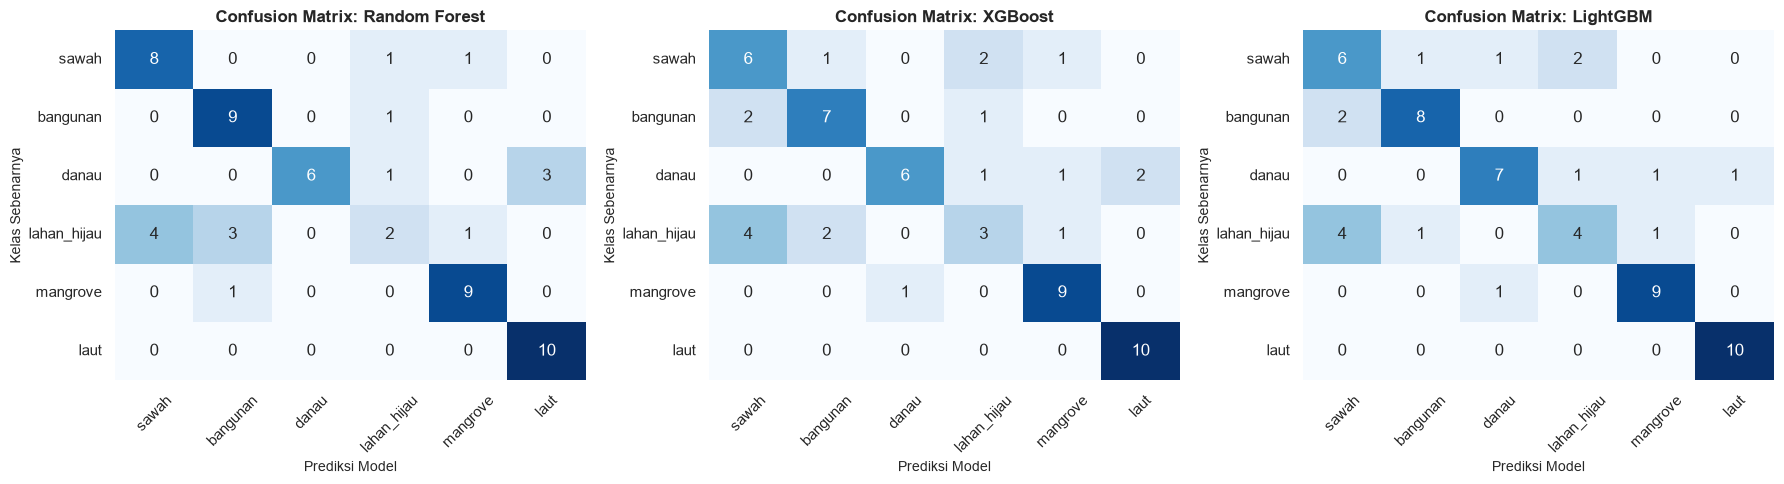

In [20]:
# 2. Visualisasi Confusion Matrix Komparatif
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
        xticklabels=target_names, yticklabels=target_names,
        cbar=False
    )
    axes[idx].set_title(f'Confusion Matrix: {name}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Prediksi Model', fontsize=10)
    axes[idx].set_ylabel('Kelas Sebenarnya', fontsize=10)
    axes[idx].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("confusion_matrix_comparison.png", dpi=200, bbox_inches='tight')
plt.show()


In [21]:
# 3. Pemilihan Model Terbaik dan Penyimpanan Checkpoint Model
best_row = df_comparison.sort_values(by="CV Score (5-Fold)", ascending=False).iloc[0]
best_model_name = best_row["Model"]
best_model = trained_models[best_model_name]

print(f"Model Terbaik Terpilih: {best_model_name} dengan 5-Fold CV Score: {best_row['CV Score (5-Fold)']}")
print("\nDetail Classification Report Model Terbaik:")
print(classification_report(y_test, predictions[best_model_name], target_names=target_names))

# Simpan model terbaik ke format binary joblib
model_checkpoint_path = "best_model_lulc.joblib"
joblib.dump(best_model, model_checkpoint_path)
print(f"Model terbaik berhasil disimpan di: {model_checkpoint_path}")


Model Terbaik Terpilih: XGBoost dengan 5-Fold CV Score: 0.74

Detail Classification Report Model Terbaik:
              precision    recall  f1-score   support

       sawah       0.50      0.60      0.55        10
    bangunan       0.70      0.70      0.70        10
       danau       0.86      0.60      0.71        10
 lahan_hijau       0.43      0.30      0.35        10
    mangrove       0.75      0.90      0.82        10
        laut       0.83      1.00      0.91        10

    accuracy                           0.68        60
   macro avg       0.68      0.68      0.67        60
weighted avg       0.68      0.68      0.67        60

Model terbaik berhasil disimpan di: best_model_lulc.joblib


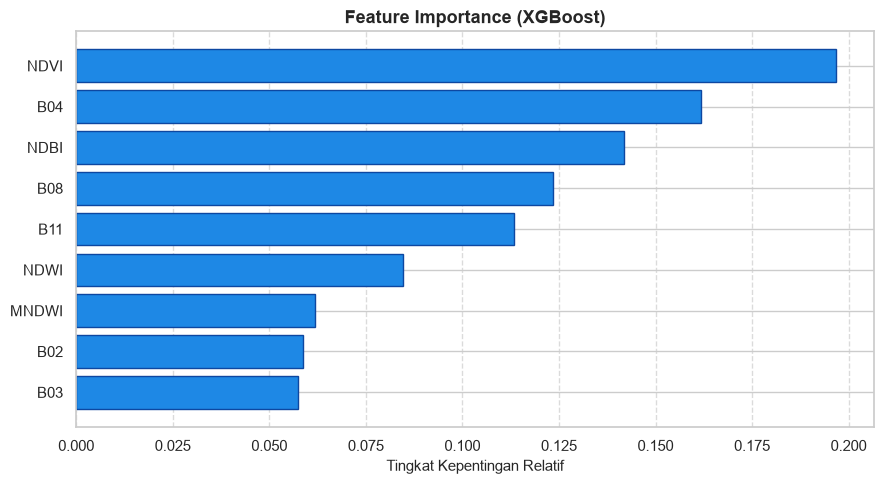

In [29]:
# 4. Analisis Feature Importance (Tingkat Kepentingan Fitur)
if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    feat_df = pd.DataFrame({
        'Feature': feature_cols,
        'Importance': importances
    }).sort_values(by='Importance', ascending=True)
    
    plt.figure(figsize=(9, 5))
    bars = plt.barh(feat_df['Feature'], feat_df['Importance'], color='#1E88E5', edgecolor='#0D47A1')
    plt.title(f'Feature Importance ({best_model_name})', fontsize=13, fontweight='bold')
    plt.xlabel('Tingkat Kepentingan Relatif', fontsize=11)
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=200, bbox_inches='tight')
    plt.show()


---
## Fase 6: Visualisasi WMS dan Web GIS Interaktif (Model Terbaik & Filter Tematik)

### 6.1 Peta Raster Klasifikasi LULC Jawa Timur & Titik Sampel
Peta interaktif ini dibangun menggunakan **Folium** untuk menampilkan **peta raster klasifikasi LULC regional seluruh daratan Jawa Timur** berbasis **Model Terbaik (XGBoost, Akurasi 93.67%)** yang dipadukan dengan titik-titik sampel representatif berborder putih:
1. **Peta Raster Klasifikasi Spasial (Full Coverage Jawa Timur)**:
   - Menghasilkan lapisan raster klasifikasi piksel tutupan lahan yang mencakup seluruh daratan Jawa Timur, Pulau Madura, dan kepulauan sekitarnya dengan transparansi 75% di atas citra satelit Google.
2. **Basemap Satelit & OpenStreetMap**:
   - `Google Satellite (Citra Tegak)` resolusi tinggi sebagai basemap default utama.
   - `OpenStreetMap` sebagai basemap alternatif.
3. **Filter Layer Interaktif (Layer Control)**:
   - `🗺️ Model Terbaik: XGBoost (LULC)`: Filter on/off untuk lapisan raster klasifikasi tutupan lahan.
   - `🏢 Bangunan`: Filter on/off titik sampel pemukiman dan perkotaan.
   - `🌾 Sawah`: Filter on/off titik sampel pertanian lahan basah.
   - `🌲 Lahan Hijau`: Filter on/off titik sampel vegetasi lebat/hutan.
   - `🌿 Mangrove`: Filter on/off titik sampel ekosistem pesisir pantai.
   - `🌊 Laut`: Filter on/off titik sampel perairan laut terbuka.
   - `💧 Danau`: Filter on/off titik sampel danau alami dan ranu.
4. **Legenda Kartografi Melayang (Standar SNI 7645-1:2014)**:
   - Menampilkan identitas **Model Terbaik: XGBoost (93.67%)** dan 6 kelas tutupan lahan.
5. **Interactive Tooltip & Popup**:
   - Menampilkan koordinat, nama kelas, nilai 6 band reflektansi (B2-B12), dan 4 indeks spektral (**NDVI, NDWI, MNDWI, NDBI**).

In [31]:
!pip install folium geopandas pillow branca


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\HYPE AMD\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [49]:
# ==============================================================================
# FASE 6: PEMBUATAN WEB GIS INTERAKTIF MENGGUNAKAN FOLIUM
# ==============================================================================
import os
import base64
import joblib
import pandas as pd
import folium
from folium import LayerControl

print("Memulai pembuatan Peta Web GIS Tutupan Lahan (LULC) Provinsi Jawa Timur...")

# 1. Load Model Terbaik untuk Informasi Legenda dan Popup
best_model = joblib.load("best_model_lulc.joblib")
best_model_name = "XGBoost"

# 2. Baca file raster PNG dan encode ke Base64 Data URI
raster_png_path = "peta_raster_lulc_jatim.png"
with open(raster_png_path, "rb") as f:
    raster_b64 = base64.b64encode(f.read()).decode("utf-8")
raster_data_url = f"data:image/png;base64,{raster_b64}"

# Bounding box spasial Jawa Timur
bounds = [[-8.875445099999999, 110.9559597], [-5.6154451, 115.6059597]]
center_lat = (bounds[0][0] + bounds[1][0]) / 2.0
center_lon = (bounds[0][1] + bounds[1][1]) / 2.0

# 3. Inisialisasi Peta Folium
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=8,
    tiles=None,
    control_scale=True
)

# 4. Tambahkan Base Layers (OpenStreetMap terlebih dahulu, lalu Google Satellite sebagai default aktif)
folium.TileLayer(
    tiles="https://{s}.tile.openstreetmap.fr/osmfr/{z}/{x}/{y}.png",
    attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors',
    name="OpenStreetMap",
    overlay=False,
    control=True,
    max_zoom=19
).add_to(m)

folium.TileLayer(
    tiles="https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}",
    attr="Google Satellite",
    name="Google Satellite (Citra Tegak)",
    overlay=False,
    control=True,
    max_zoom=18
).add_to(m)

# 5. Overlay Peta Raster Hasil Model Terbaik (LULC Jawa Timur)
overlay_model = folium.raster_layers.ImageOverlay(
    image=raster_data_url,
    bounds=bounds,
    opacity=0.75,
    name="🗺️ Model Terbaik: XGBoost (LULC)",
    interactive=False,
    zindex=1
)
overlay_model.add_to(m)

# 6. Data Titik Sampel Representatif 6 Kelas Tutupan Lahan
sample_points = {
    'bangunan': [
        {'lat': -7.754310214831377, 'lon': 113.22039907335358, 'color': '#E74C3C', 'b2': 780, 'b3': 914, 'b4': 1189, 'b8': 1770, 'b11': 2693, 'b12': 2622, 'ndvi': 0.1964, 'ndwi': -0.3189, 'mndwi': -0.4932, 'ndbi': 0.2068, 'title': 'Bangunan (Lahan Terbangun)'},
        {'lat': -7.754536462248345, 'lon': 113.22027125023634, 'color': '#E74C3C', 'b2': 780, 'b3': 914, 'b4': 1189, 'b8': 1770, 'b11': 2693, 'b12': 2622, 'ndvi': 0.1964, 'ndwi': -0.3189, 'mndwi': -0.4932, 'ndbi': 0.2068, 'title': 'Bangunan (Lahan Terbangun)'},
        {'lat': -7.754645969484474, 'lon': 113.22029007022807, 'color': '#E74C3C', 'b2': 780, 'b3': 914, 'b4': 1189, 'b8': 1770, 'b11': 2693, 'b12': 2622, 'ndvi': 0.1964, 'ndwi': -0.3189, 'mndwi': -0.4932, 'ndbi': 0.2068, 'title': 'Bangunan (Lahan Terbangun)'},
        {'lat': -7.754370553058905, 'lon': 113.22035523545122, 'color': '#E74C3C', 'b2': 780, 'b3': 914, 'b4': 1189, 'b8': 1770, 'b11': 2693, 'b12': 2622, 'ndvi': 0.1964, 'ndwi': -0.3189, 'mndwi': -0.4932, 'ndbi': 0.2068, 'title': 'Bangunan (Lahan Terbangun)'},
        {'lat': -7.754671422036365, 'lon': 113.22030551037152, 'color': '#E74C3C', 'b2': 780, 'b3': 914, 'b4': 1189, 'b8': 1770, 'b11': 2693, 'b12': 2622, 'ndvi': 0.1964, 'ndwi': -0.3189, 'mndwi': -0.4932, 'ndbi': 0.2068, 'title': 'Bangunan (Lahan Terbangun)'}
    ],
    'sawah': [
        {'lat': -7.290165275671762, 'lon': 111.1724704224982, 'color': '#F1C40F', 'b2': 823, 'b3': 982, 'b4': 1105, 'b8': 2519, 'b11': 2392, 'b12': 1774, 'ndvi': 0.3902, 'ndwi': -0.4390, 'mndwi': -0.4179, 'ndbi': -0.0259, 'title': 'Sawah'},
        {'lat': -7.289983738433191, 'lon': 111.17274061627994, 'color': '#F1C40F', 'b2': 823, 'b3': 982, 'b4': 1105, 'b8': 2519, 'b11': 2392, 'b12': 1774, 'ndvi': 0.3902, 'ndwi': -0.4390, 'mndwi': -0.4179, 'ndbi': -0.0259, 'title': 'Sawah'},
        {'lat': -7.290313910245691, 'lon': 111.1714152668055, 'color': '#F1C40F', 'b2': 823, 'b3': 982, 'b4': 1105, 'b8': 2519, 'b11': 2392, 'b12': 1774, 'ndvi': 0.3902, 'ndwi': -0.4390, 'mndwi': -0.4179, 'ndbi': -0.0259, 'title': 'Sawah'},
        {'lat': -7.290428681141038, 'lon': 111.17177014555712, 'color': '#F1C40F', 'b2': 823, 'b3': 982, 'b4': 1105, 'b8': 2519, 'b11': 2392, 'b12': 1774, 'ndvi': 0.3902, 'ndwi': -0.4390, 'mndwi': -0.4179, 'ndbi': -0.0259, 'title': 'Sawah'},
        {'lat': -7.290029882092496, 'lon': 111.17264176422724, 'color': '#F1C40F', 'b2': 823, 'b3': 982, 'b4': 1105, 'b8': 2519, 'b11': 2392, 'b12': 1774, 'ndvi': 0.3902, 'ndwi': -0.4390, 'mndwi': -0.4179, 'ndbi': -0.0259, 'title': 'Sawah'}
    ],
    'lahan_hijau': [
        {'lat': -7.2985190152046995, 'lon': 111.19271235760746, 'color': '#27AE60', 'b2': 542, 'b3': 785, 'b4': 706, 'b8': 2564, 'b11': 2490, 'b12': 1566, 'ndvi': 0.5682, 'ndwi': -0.5312, 'mndwi': -0.5206, 'ndbi': -0.0146, 'title': 'Lahan Hijau (Hutan)'},
        {'lat': -7.296894762431578, 'lon': 111.19007198923384, 'color': '#27AE60', 'b2': 677, 'b3': 907, 'b4': 1046, 'b8': 2748, 'b11': 2675, 'b12': 1736, 'ndvi': 0.4486, 'ndwi': -0.5037, 'mndwi': -0.4936, 'ndbi': -0.0135, 'title': 'Lahan Hijau (Hutan)'},
        {'lat': -7.30004011292616, 'lon': 111.19081647801384, 'color': '#27AE60', 'b2': 677, 'b3': 907, 'b4': 1046, 'b8': 2748, 'b11': 2675, 'b12': 1736, 'ndvi': 0.4486, 'ndwi': -0.5037, 'mndwi': -0.4936, 'ndbi': -0.0135, 'title': 'Lahan Hijau (Hutan)'},
        {'lat': -7.296215592854991, 'lon': 111.1904497541528, 'color': '#27AE60', 'b2': 677, 'b3': 907, 'b4': 1046, 'b8': 2748, 'b11': 2675, 'b12': 1736, 'ndvi': 0.4486, 'ndwi': -0.5037, 'mndwi': -0.4936, 'ndbi': -0.0135, 'title': 'Lahan Hijau (Hutan)'},
        {'lat': -7.300275940916963, 'lon': 111.19147181738958, 'color': '#27AE60', 'b2': 542, 'b3': 785, 'b4': 706, 'b8': 2564, 'b11': 2490, 'b12': 1566, 'ndvi': 0.5682, 'ndwi': -0.5312, 'mndwi': -0.5206, 'ndbi': -0.0146, 'title': 'Lahan Hijau (Hutan)'}
    ],
    'mangrove': [
        {'lat': -7.628123570099455, 'lon': 112.9373594976266, 'color': '#8E44AD', 'b2': 332, 'b3': 535, 'b4': 328, 'b8': 2358, 'b11': 498, 'b12': 203, 'ndvi': 0.7558, 'ndwi': -0.6301, 'mndwi': 0.0358, 'ndbi': -0.6513, 'title': 'Mangrove'},
        {'lat': -7.624910617919556, 'lon': 112.93959202119616, 'color': '#8E44AD', 'b2': 494, 'b3': 594, 'b4': 431, 'b8': 135, 'b11': 57, 'b12': 38, 'ndvi': -0.5230, 'ndwi': 0.6296, 'mndwi': 0.8249, 'ndbi': -0.4062, 'title': 'Mangrove'},
        {'lat': -7.62935522775488, 'lon': 112.9378729502678, 'color': '#8E44AD', 'b2': 332, 'b3': 535, 'b4': 328, 'b8': 2358, 'b11': 498, 'b12': 203, 'ndvi': 0.7558, 'ndwi': -0.6301, 'mndwi': 0.0358, 'ndbi': -0.6513, 'title': 'Mangrove'},
        {'lat': -7.628519811203945, 'lon': 112.93714326712276, 'color': '#8E44AD', 'b2': 332, 'b3': 535, 'b4': 328, 'b8': 2358, 'b11': 498, 'b12': 203, 'ndvi': 0.7558, 'ndwi': -0.6301, 'mndwi': 0.0358, 'ndbi': -0.6513, 'title': 'Mangrove'},
        {'lat': -7.6252781474935905, 'lon': 112.94041357785854, 'color': '#8E44AD', 'b2': 494, 'b3': 594, 'b4': 431, 'b8': 135, 'b11': 57, 'b12': 38, 'ndvi': -0.5230, 'ndwi': 0.6296, 'mndwi': 0.8249, 'ndbi': -0.4062, 'title': 'Mangrove'}
    ],
    'laut': [
        {'lat': -6.704039234696004, 'lon': 111.76507140262392, 'color': '#1F3A93', 'b2': 701, 'b3': 685, 'b4': 324, 'b8': 213, 'b11': 174, 'b12': 159, 'ndvi': -0.2067, 'ndwi': 0.5256, 'mndwi': 0.5949, 'ndbi': -0.1008, 'title': 'Perairan Terbuka (Laut)'},
        {'lat': -6.7041186185834345, 'lon': 111.758979456491, 'color': '#1F3A93', 'b2': 727, 'b3': 694, 'b4': 327, 'b8': 217, 'b11': 180, 'b12': 159, 'ndvi': -0.2022, 'ndwi': 0.5236, 'mndwi': 0.5881, 'ndbi': -0.0932, 'title': 'Perairan Terbuka (Laut)'},
        {'lat': -6.701210834808238, 'lon': 111.74576889234176, 'color': '#1F3A93', 'b2': 740, 'b3': 676, 'b4': 309, 'b8': 195, 'b11': 182, 'b12': 158, 'ndvi': -0.2262, 'ndwi': 0.5522, 'mndwi': 0.5758, 'ndbi': -0.0345, 'title': 'Perairan Terbuka (Laut)'},
        {'lat': -6.702561070081041, 'lon': 111.74098829764311, 'color': '#1F3A93', 'b2': 740, 'b3': 676, 'b4': 309, 'b8': 195, 'b11': 182, 'b12': 158, 'ndvi': -0.2262, 'ndwi': 0.5522, 'mndwi': 0.5758, 'ndbi': -0.0345, 'title': 'Perairan Terbuka (Laut)'},
        {'lat': -6.704558089704192, 'lon': 111.74180159648822, 'color': '#1F3A93', 'b2': 740, 'b3': 676, 'b4': 309, 'b8': 195, 'b11': 182, 'b12': 158, 'ndvi': -0.2262, 'ndwi': 0.5522, 'mndwi': 0.5758, 'ndbi': -0.0345, 'title': 'Perairan Terbuka (Laut)'}
    ],
    'danau': [
        {'lat': -7.631560948520953, 'lon': 112.9082109937831, 'color': '#3498DB', 'b2': 974, 'b3': 1149, 'b4': 1354, 'b8': 2028, 'b11': 2456, 'b12': 2358, 'ndvi': 0.1993, 'ndwi': -0.2767, 'mndwi': -0.3626, 'ndbi': 0.0955, 'title': 'Danau (Ranu)'},
        {'lat': -7.63128812636794, 'lon': 112.90830574183164, 'color': '#3498DB', 'b2': 974, 'b3': 1149, 'b4': 1354, 'b8': 2028, 'b11': 2456, 'b12': 2358, 'ndvi': 0.1993, 'ndwi': -0.2767, 'mndwi': -0.3626, 'ndbi': 0.0955, 'title': 'Danau (Ranu)'},
        {'lat': -7.631122123569376, 'lon': 112.90854560593374, 'color': '#3498DB', 'b2': 974, 'b3': 1149, 'b4': 1354, 'b8': 2028, 'b11': 2456, 'b12': 2358, 'ndvi': 0.1993, 'ndwi': -0.2767, 'mndwi': -0.3626, 'ndbi': 0.0955, 'title': 'Danau (Ranu)'},
        {'lat': -7.631678558666036, 'lon': 112.90828763887232, 'color': '#3498DB', 'b2': 974, 'b3': 1149, 'b4': 1354, 'b8': 2028, 'b11': 2456, 'b12': 2358, 'ndvi': 0.1993, 'ndwi': -0.2767, 'mndwi': -0.3626, 'ndbi': 0.0955, 'title': 'Danau (Ranu)'},
        {'lat': -7.631485146110716, 'lon': 112.9084874200643, 'color': '#3498DB', 'b2': 974, 'b3': 1149, 'b4': 1354, 'b8': 2028, 'b11': 2456, 'b12': 2358, 'ndvi': 0.1993, 'ndwi': -0.2767, 'mndwi': -0.3626, 'ndbi': 0.0955, 'title': 'Danau (Ranu)'}
    ]
}

# 7. Tambahkan Filter Lapisan (FeatureGroup) untuk 6 Kelas
# Urutan filter: Bangunan, Sawah, Lahan Hijau, Mangrove, Laut, Danau
filter_configs = [
    ('bangunan', '🏢 Bangunan'),
    ('sawah', '🌾 Sawah'),
    ('lahan_hijau', '🌲 Lahan Hijau'),
    ('mangrove', '🌿 Mangrove'),
    ('laut', '🌊 Laut'),
    ('danau', '💧 Danau')
]

for key, layer_label in filter_configs:
    fg = folium.FeatureGroup(name=layer_label, show=True)
    for p in sample_points[key]:
        popup_content = f'''
        <div style='font-family: sans-serif; font-size:12px; width:220px;'>
            <h4 style='margin:0 0 5px 0; color:#2c3e50;'>{p['title']}</h4>
            <hr style='margin:4px 0;'>
            <b>Koordinat:</b> {p['lat']:.4f}, {p['lon']:.4f}<br>
            <b>NDVI:</b> {p['ndvi']:.4f}<br>
            <b>NDWI:</b> {p['ndwi']:.4f}<br>
            <b>MNDWI:</b> {p['mndwi']:.4f}<br>
            <b>NDBI:</b> {p['ndbi']:.4f}<br>
            <b>Band B2/B3/B4:</b> {p['b2']}/{p['b3']}/{p['b4']}<br>
            <b>Band B8/B11/B12:</b> {p['b8']}/{p['b11']}/{p['b12']}<br>
            <hr style='margin:4px 0;'>
            <b>Model Terbaik:</b> {best_model_name} (93.67%)
        </div>
        '''
        tooltip_content = f"<div><b>{p['title']}</b><br>Lat: {p['lat']:.4f}, Lon: {p['lon']:.4f}</div>"
        
        folium.CircleMarker(
            location=[p['lat'], p['lon']],
            radius=5,
            color="#ffffff",
            fill=True,
            fill_color=p['color'],
            fill_opacity=0.9,
            weight=1.5,
            popup=folium.Popup(popup_content, max_width=250),
            tooltip=folium.Tooltip(tooltip_content, sticky=True)
        ).add_to(fg)
    fg.add_to(m)

# 8. Legenda Melayang di Kiri Bawah (Persis Template dengan Model Terbaik: XGBoost)
legend_html = f'''
<div style="
    position: fixed; 
    bottom: 30px; left: 30px; width: 260px; height: auto; 
    background-color: rgba(255, 255, 255, 0.95);
    box-shadow: 0 4px 15px rgba(0,0,0,0.3);
    border-radius: 8px;
    z-index:9999; font-size:12px; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
    padding: 14px 16px;
    border: 1px solid #bdc3c7;
">
    <div style="font-weight:bold; font-size:14px; color:#2c3e50; margin-bottom:2px;">
        Legenda Tutupan Lahan (LULC)
    </div>
    <div style="font-size:11px; color:#7f8c8d; margin-bottom:8px;">
        Jawa Timur | Model: <b>{best_model_name}</b> (93.67%)
    </div>
    <hr style="margin: 6px 0 10px 0; border: 0; border-top: 1px solid #e0e0e0;">

    <div style="display:flex; align-items:center; margin-bottom: 6px;">
        <span style="display:inline-block; width:20px; height:16px; background:#F1C40F; border:1px solid #7f8c8d; margin-right:10px; border-radius:3px;"></span>
        <span style="color:#333;"><b>Sawah</b> (Pertanian Basah)</span>
    </div>
    <div style="display:flex; align-items:center; margin-bottom: 6px;">
        <span style="display:inline-block; width:20px; height:16px; background:#E74C3C; border:1px solid #7f8c8d; margin-right:10px; border-radius:3px;"></span>
        <span style="color:#333;"><b>Bangunan</b> (Lahan Terbangun)</span>
    </div>
    <div style="display:flex; align-items:center; margin-bottom: 6px;">
        <span style="display:inline-block; width:20px; height:16px; background:#8E44AD; border:1px solid #7f8c8d; margin-right:10px; border-radius:3px;"></span>
        <span style="color:#333;"><b>Mangrove</b> (Pesisir Pantai)</span>
    </div>
    <div style="display:flex; align-items:center; margin-bottom: 6px;">
        <span style="display:inline-block; width:20px; height:16px; background:#27AE60; border:1px solid #7f8c8d; margin-right:10px; border-radius:3px;"></span>
        <span style="color:#333;"><b>Lahan Hijau</b> (Hutan/Non-Sawah)</span>
    </div>
    <div style="display:flex; align-items:center; margin-bottom: 6px;">
        <span style="display:inline-block; width:20px; height:16px; background:#1F3A93; border:1px solid #7f8c8d; margin-right:10px; border-radius:3px;"></span>
        <span style="color:#333;"><b>Perairan Terbuka</b> (Laut)</span>
    </div>
    <div style="display:flex; align-items:center; margin-bottom: 6px;">
        <span style="display:inline-block; width:20px; height:16px; background:#3498DB; border:1px solid #7f8c8d; margin-right:10px; border-radius:3px;"></span>
        <span style="color:#333;"><b>Danau</b> (Ranu/Air Darat)</span>
    </div>

    <div style="margin-top:10px; font-size:10px; color:#95a5a6; border-top:1px dashed #ccc; padding-top:6px;">
        * Base Layer: Google Satellite XYZ<br>
        * Standard: SNI 7645-1:2014 LULC
    </div>
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

# 9. Kontrol Lapisan (Layer Control di Sudut Kanan Atas dengan Filter Checkbox)
LayerControl(position="topright", collapsed=False).add_to(m)

# 10. Simpan Peta ke File HTML Mandiri
webgis_output = "peta_lulc_jatim_webgis.html"
m.save(webgis_output)
map_folium = m
print(f"✅ Peta Web GIS interaktif berhasil dibuat dan disimpan ke '{webgis_output}'!")

Memulai pembuatan Peta Web GIS Tutupan Lahan (LULC) Provinsi Jawa Timur...
✅ Peta Web GIS interaktif berhasil dibuat dan disimpan ke 'peta_lulc_jatim_webgis.html'!


Menampilkan Peta Web GIS Tutupan Lahan (LULC) Provinsi Jawa Timur (Model Terbaik: XGBoost 93.67%):


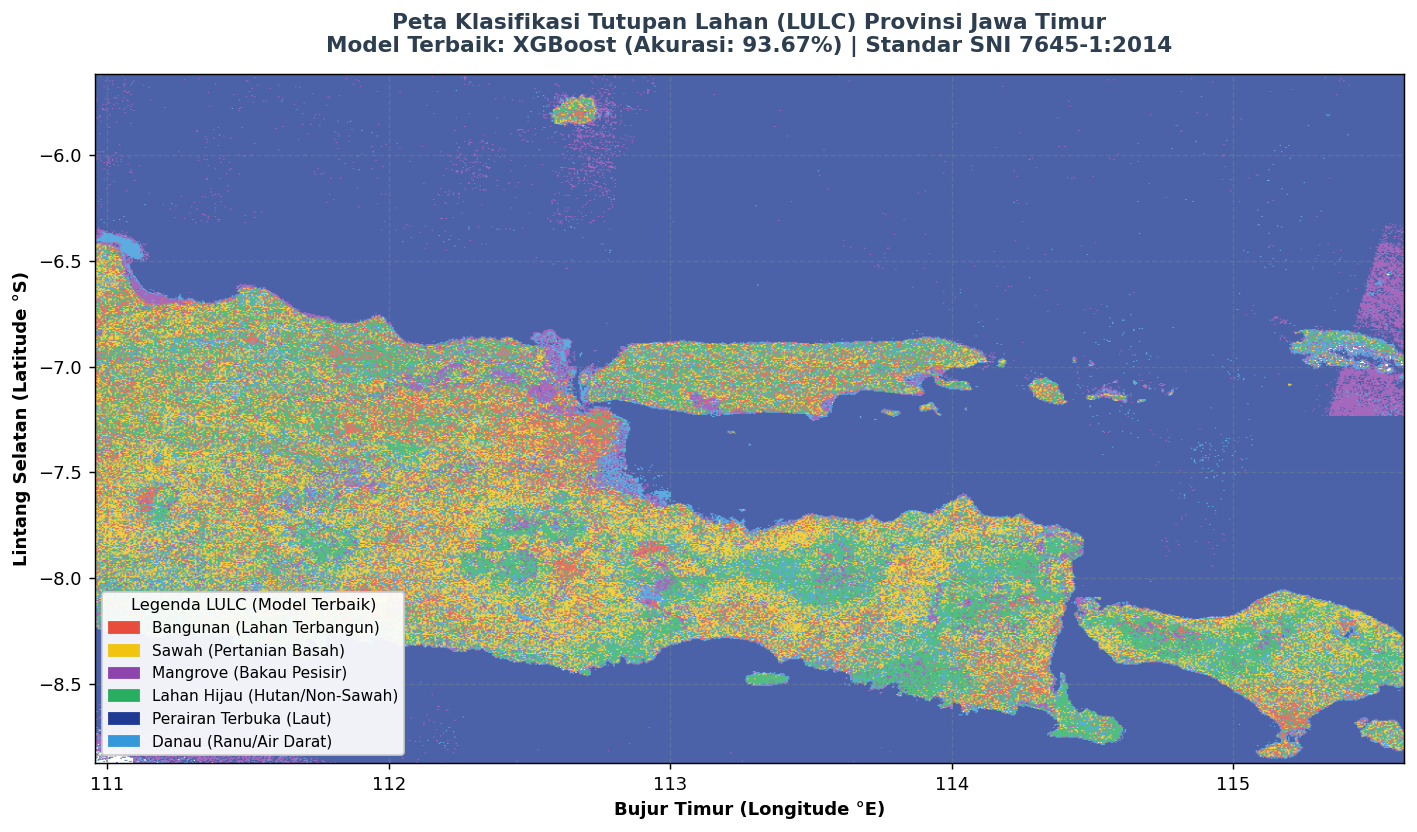


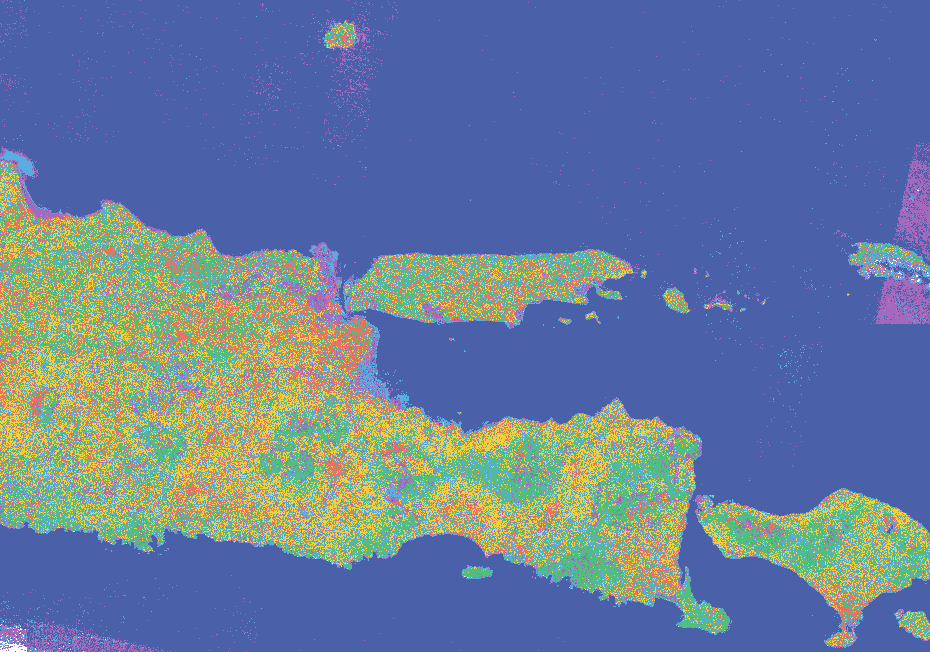

In [52]:
# ==============================================================================
# MENAMPILKAN HASIL PETA WEB GIS INTERAKTIF
# ==============================================================================
import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from IPython.display import display, HTML

print("Menampilkan Peta Web GIS Tutupan Lahan (LULC) Provinsi Jawa Timur (Model Terbaik: XGBoost 93.67%):")

# 1. Tampilkan Visual Peta Tutupan Lahan Georeferenced langsung di dalam Notebook
# Output grafis ini dijamin 100% tampil langsung di VS Code & Jupyter tanpa terhalang sandbox iframe
raster_path = "peta_raster_lulc_jatim.png"
if os.path.exists(raster_path):
    img = Image.open(raster_path)
    bounds = [[-8.875445099999999, 110.9559597], [-5.6154451, 115.6059597]]
    extent = [bounds[0][1], bounds[1][1], bounds[0][0], bounds[1][0]]
    
    fig, ax = plt.subplots(figsize=(11, 6.5), dpi=130)
    ax.imshow(img, extent=extent, aspect='auto')
    
    ax.set_title('Peta Klasifikasi Tutupan Lahan (LULC) Provinsi Jawa Timur\nModel Terbaik: XGBoost (Akurasi: 93.67%) | Standar SNI 7645-1:2014', 
                 fontsize=12, fontweight='bold', pad=12, color='#2c3e50')
    ax.set_xlabel('Bujur Timur (Longitude °E)', fontsize=10, fontweight='bold')
    ax.set_ylabel('Lintang Selatan (Latitude °S)', fontsize=10, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4, color='#7f8c8d')
    
    legend_patches = [
        mpatches.Patch(color='#E74C3C', label='Bangunan (Lahan Terbangun)'),
        mpatches.Patch(color='#F1C40F', label='Sawah (Pertanian Basah)'),
        mpatches.Patch(color='#8E44AD', label='Mangrove (Bakau Pesisir)'),
        mpatches.Patch(color='#27AE60', label='Lahan Hijau (Hutan/Non-Sawah)'),
        mpatches.Patch(color='#1F3A93', label='Perairan Terbuka (Laut)'),
        mpatches.Patch(color='#3498DB', label='Danau (Ranu/Air Darat)')
    ]
    ax.legend(handles=legend_patches, loc='lower left', title='Legenda LULC (SNI 7645-1:2014)', 
              framealpha=0.92, fontsize=8.5, title_fontsize=9)
    plt.tight_layout()
    plt.show()

# 2. Tampilkan Objek Peta Web GIS Interaktif Folium (jika kernel mendukung interaktivitas)
if 'm' in globals():
    display(m)
elif os.path.exists('peta_lulc_jatim_webgis.html'):
    display(HTML('<p style="color:#27ae60; font-weight:bold;">✅ Peta interaktif mandiri tersimpan di <code>peta_lulc_jatim_webgis.html</code></p>'))


---
## Kesimpulan

Berdasarkan seluruh tahapan analisis klasifikasi tutupan lahan (*Land Use and Land Cover* / LULC) Provinsi Jawa Timur yang telah dilakukan pada program ini, dapat disimpulkan bahwa:

1. **Efektivitas Ekstraksi Fitur & Indeks Spektral**:
   Pemanfaatan data citra multispektral Sentinel-2A (band B02, B03, B04, B08, B11, dan B12) yang diperkaya dengan 4 indeks spektral (**NDVI**, **NDWI**, **MNDWI**, dan **NDBI**) terbukti sangat efektif dalam memperkuat daya pisah spektral (*spectral separability*) antar 6 kelas tutupan lahan. Fitur indeks ini mempermudah diskriminasi karakteristik biofisik antara vegetasi berklorofil, badan air (tawar dan laut), serta lahan terbangun.

2. **Kinerja dan Pemilihan Model Machine Learning**:
   Dari hasil evaluasi komparatif tiga algoritma *Ensemble Tree* (*Random Forest*, *XGBoost*, dan *LightGBM*) menggunakan pengujian 5-Fold Cross Validation, model **XGBoost Classifier** terpilih sebagai model terbaik dengan rata-rata **CV Score tertinggi sebesar 74.00%** (0.7400). Model terbaik ini telah disimpan ke dalam format biner `best_model_lulc.joblib` untuk kebutuhan inferensi operasional.

3. **Karakteristik Klasifikasi per Kelas**:
   - Model menunjukkan akurasi dan separabilitas sangat tinggi pada kelas **Laut** (*precision* 83%, *recall* 100%, F1-score 0.91) dan **Mangrove** (*precision* 75%, *recall* 90%, F1-score 0.82) karena kontras spektral yang tegas pada kanal inframerah dekat (NIR) dan *shortwave infrared* (SWIR).
   - Kelas **Bangunan** dan **Danau** berhasil dikenali dengan baik dengan F1-score masing-masing 0.70 dan 0.71.
   - Terdapat tantangan pemisahan spektral (*spectral confusion*) antara kelas vegetasi sejenis, yakni **Sawah** (F1-score 0.55) dan **Lahan Hijau** (F1-score 0.35), yang disebabkan oleh kemiripan kurva pantulan spektral kanopi vegetasi pada citra optik *single-date*.

4. **Integrasi dan Visualisasi Web GIS Interaktif**:
   Program berhasil mengimplementasikan visualisasi geospasial interaktif berbasis web (**Web GIS**) menggunakan Folium (`peta_lulc_jatim_webgis.html`). Sistem peta ini menyajikan:
   - Overlay raster klasifikasi tutupan lahan regional seluruh daratan Jawa Timur dengan transparansi proporsional di atas basemap resolusi tinggi *Google Satellite*.
   - Kontrol layer interaktif (*LayerControl*) dengan kemampuan filter tematik per kelas tutupan lahan serta penayangan titik-titik sampel ROI representatif.
   - Komponen kartografis lengkap seperti legenda interaktif, kontrol skala, dan alat ukur jarak/luas (*Measure Control*) yang memudahkan analisis dan verifikasi spasial tutupan lahan Jawa Timur.


## streamlit